# 🏦 Loan Approval Prediction: End-to-End Machine Learning Pipeline

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/)

## Project Overview & Objectives
Automated loan decisioning systems enable financial institutions to assess credit risk consistently, objectively, and rapidly.

In this notebook, we build, evaluate, and compare an end-to-end Machine Learning pipeline across **three distinct algorithmic paradigms**:
1. **Gaussian Naive Bayes**: A probabilistic baseline assuming conditional feature independence.
2. **Support Vector Machine (RBF Kernel)**: A non-linear maximum-margin hyperplane classifier.
3. **Decision Tree (CART)**: A non-parametric tree structure providing direct visual interpretability.

### End-to-End Workflow Sequence:
- **1. Data Ingestion & Target Formulation**
- **2. Stratified Train-Test Split (80/20)**
- **3. Preprocessing & Data Transformation Pipeline (ColumnTransformer)**
- **4. Model Training & Pipeline Integration (All 3 Models)**
- **5. Model Evaluation on Holdout Test Set (Metrics & Reports)**
- **6. Comparative Performance Analysis & Visualizations (Bar Charts & Confusion Matrices)**
- **7. Decision Tree Logic & Interpretability Visualization (`plot_tree`)**
- **8. Multi-Dimensional Benchmark & Trade-off Analysis (Latency & Complexity)**
- **9. Model Serialization & Production Export (`.pkl` Artifacts)**


In [1]:
import os
import warnings
warnings.filterwarnings('ignore')
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Scikit-Learn Pipeline & Models
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree

# Evaluation Metrics
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, balanced_accuracy_score, confusion_matrix,
    classification_report, ConfusionMatrixDisplay
)

# Data Ingestion: GitHub -> Local File -> Manual Upload Fallback
DATA_URL        = "https://raw.githubusercontent.com/Abhijeet0848/loan-approval-prediction/main/Data/loan.csv"
LOCAL_CANDIDATES = ("Data/loan.csv", "../Data/loan.csv")

def load_data() -> pd.DataFrame:
    # 1) Try GitHub
    try:
        return pd.read_csv(DATA_URL)
    except Exception:
        pass

    # 2) Fall back to local file
    for path in LOCAL_CANDIDATES:
        if os.path.exists(path):
            return pd.read_csv(path)

    # 3) Fall back to manual file upload if running in Google Colab
    try:
        from google.colab import files
        print("📁 Falling back to manual upload. Please select loan.csv:")
        uploaded = files.upload()
        if uploaded:
            file_name = list(uploaded.keys())[0]
            return pd.read_csv(file_name)
    except Exception:
        pass

    raise FileNotFoundError("GitHub fetch failed, no local file found, and no file uploaded.")

df = load_data()
print("✅ Data loaded successfully")

✅ Data loaded successfully


## 1. Feature & Target Formulation
We separate the identifier metadata (`Loan_ID`) and the target variable (`Loan_Status`).
The binary target is mapped as:
- `Y` (Approved) $\rightarrow$ `1`
- `N` (Rejected) $\rightarrow$ `0`


In [2]:
# Features X (drop identifier and target), Target y (mapped to binary 1/0)
X = df.drop(['Loan_ID', 'Loan_Status'], axis=1)
y = df['Loan_Status'].map({'Y': 1, 'N': 0})

print("Feature Columns (11 total):")
print(list(X.columns))
print("\nTarget Distribution:")
print(y.value_counts(normalize=True).map(lambda p: f"{p*100:.1f}%"))


Feature Columns (11 total):
['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History', 'Property_Area']

Target Distribution:
Loan_Status
1    74.4%
0    25.7%
Name: proportion, dtype: object


## 2. Stratified Train-Test Split
To evaluate genuine out-of-sample generalization, we hold out 20% of the data using **stratified sampling** (`stratify=y`) so that the ratio of approvals to rejections remains identical between training and test sets.


In [3]:
# Stratified 80/20 train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Training Set : {X_train.shape[0]} samples ({y_train.sum()} approved, {len(y_train)-y_train.sum()} rejected)")
print(f"Testing Set  : {X_test.shape[0]} samples ({y_test.sum()} approved, {len(y_test)-y_test.sum()} rejected)")


Training Set : 8000 samples (5948 approved, 2052 rejected)
Testing Set  : 2000 samples (1487 approved, 513 rejected)


## 3. Preprocessing & Data Transformation Pipelines
To ensure robust generalization and prevent data leakage, we structure our preprocessing pipelines using `ColumnTransformer`:
- **Standard Scaled Pipeline** (for Naive Bayes & SVM): Imputes missing values, encodes categories via `OneHotEncoder`, and standardizes numerical variables using `StandardScaler`.
- **Unscaled Pipeline** (for Decision Tree): Imputes missing values and encodes categories without `StandardScaler`. Decision Trees are invariant to monotonic transformations, so keeping original scales preserves **real dollar amounts and 0/1 credit scores** for maximum visual interpretability.


In [4]:
# Identify numerical and categorical modalities
num_cols = X.select_dtypes(include=['int64', 'float64']).columns
cat_cols = X.select_dtypes(include=['object']).columns

# 1. Scaled preprocessor (for Naive Bayes and SVM)
preprocessor_scaled = ColumnTransformer([
    ('num', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]), num_cols),
    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore'))
    ]), cat_cols)
])

# 2. Unscaled preprocessor (for Decision Tree - retains real-world $ and credit units)
preprocessor_tree = ColumnTransformer([
    ('num', Pipeline([
        ('imputer', SimpleImputer(strategy='median'))
    ]), num_cols),
    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore'))
    ]), cat_cols)
])

print(f"Numeric columns ({len(num_cols)}):", list(num_cols))
print(f"Categorical columns ({len(cat_cols)}):", list(cat_cols))
print("✅ Both preprocessing pipelines configured successfully!")


Numeric columns (5): ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History']
Categorical columns (6): ['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'Property_Area']
✅ Both preprocessing pipelines configured successfully!


## 4. Model Training & Pipeline Integration
We encapsulate the preprocessor and each classifier into clean, leak-free `Pipeline` objects. All three models are trained on the training partition (`X_train`, `y_train`):
1. **Naive Bayes (`GaussianNB`)**: Fast probabilistic baseline using Bayes' Theorem with Gaussian class priors.
2. **Support Vector Machine (`SVC(kernel='rbf')`)**: Maximum-margin hyperplane classifier mapped via non-linear RBF kernel.
3. **Decision Tree (`DecisionTreeClassifier(max_depth=4)`)**: White-box rule-based classifier providing transparent loan decision logic.


In [5]:
# 1. Naive Bayes Model (GaussianNB)
nb_model = Pipeline([
    ('preprocessor', preprocessor_scaled),
    ('classifier', GaussianNB())
])
nb_model.fit(X_train, y_train)
print("✅ Model 1: Naive Bayes trained successfully!")

# 2. Support Vector Machine (RBF Kernel)
svm_model = Pipeline([
    ('preprocessor', preprocessor_scaled),
    ('classifier', SVC(kernel='rbf', C=1.0, probability=True, random_state=42))
])
svm_model.fit(X_train, y_train)
print("✅ Model 2: SVM (RBF) trained successfully!")

# 3. Decision Tree Model (max_depth=4, real dollar units)
dt_model = Pipeline([
    ('preprocessor', preprocessor_tree),
    ('classifier', DecisionTreeClassifier(max_depth=4, random_state=42))
])
dt_model.fit(X_train, y_train)
print("✅ Model 3: Decision Tree trained successfully!")


✅ Model 1: Naive Bayes trained successfully!


✅ Model 2: SVM (RBF) trained successfully!
✅ Model 3: Decision Tree trained successfully!


## 5. Model Evaluation on Holdout Test Set
We evaluate all three models on the unseen 20% holdout test set using Accuracy, ROC-AUC, Confusion Matrices, and Classification Reports:
1. **Model 1: Naive Bayes (`GaussianNB`)**
2. **Model 2: Support Vector Machine (`SVC RBF Kernel`)**
3. **Model 3: Decision Tree (`DecisionTreeClassifier(max_depth=4)`)**


In [6]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_auc_score

def evaluate_model(name, model):
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    
    print(f"\n{'='*50}")
    print(f"  📊 {name}")
    print(f"{'='*50}")
    print(f"Accuracy : {accuracy_score(y_test, y_pred):.4f} ({accuracy_score(y_test, y_pred)*100:.2f}%)")
    print(f"ROC-AUC  : {roc_auc_score(y_test, y_prob):.4f}")
    print("\nConfusion Matrix:")
    print(confusion_matrix(y_test, y_pred))
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred))

# 1. Evaluate Naive Bayes
evaluate_model("Model 1: Naive Bayes", nb_model)

# 2. Evaluate Support Vector Machine
evaluate_model("Model 2: SVM (RBF Kernel)", svm_model)

# 3. Evaluate Decision Tree
evaluate_model("Model 3: Decision Tree (max_depth=4)", dt_model)



  📊 Model 1: Naive Bayes
Accuracy : 0.8740 (87.40%)
ROC-AUC  : 0.8172

Confusion Matrix:
[[ 312  201]
 [  51 1436]]

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.61      0.71       513
           1       0.88      0.97      0.92      1487

    accuracy                           0.87      2000
   macro avg       0.87      0.79      0.82      2000
weighted avg       0.87      0.87      0.87      2000




  📊 Model 2: SVM (RBF Kernel)
Accuracy : 0.8850 (88.50%)
ROC-AUC  : 0.8237

Confusion Matrix:
[[ 310  203]
 [  27 1460]]

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.60      0.73       513
           1       0.88      0.98      0.93      1487

    accuracy                           0.89      2000
   macro avg       0.90      0.79      0.83      2000
weighted avg       0.89      0.89      0.88      2000


  📊 Model 3: Decision Tree (max_depth=4)
Accuracy : 0.8845 (88.45%)
ROC-AUC  : 0.8311

Confusion Matrix:
[[ 311  202]
 [  29 1458]]

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.61      0.73       513
           1       0.88      0.98      0.93      1487

    accuracy                           0.88      2000
   macro avg       0.90      0.79      0.83      2000
weighted avg       0.89      0.88      0.88      2000



## 6. Comparative Performance Analysis & Visualization
We consolidate test set performance across all three algorithms into a structured comparison table, followed by side-by-side metric bar charts and confusion matrix heatmaps.


In [7]:
# Predictions and probabilities on test set
nb_preds = nb_model.predict(X_test)
nb_probs = nb_model.predict_proba(X_test)[:, 1]

svm_preds = svm_model.predict(X_test)
svm_probs = svm_model.predict_proba(X_test)[:, 1]

dt_preds = dt_model.predict(X_test)
dt_probs = dt_model.predict_proba(X_test)[:, 1]

# Build comparison DataFrame
df_comparison = pd.DataFrame({
    "Model": ["Naive Bayes", "SVM (RBF)", "Decision Tree"],
    "Accuracy": [
        accuracy_score(y_test, nb_preds),
        accuracy_score(y_test, svm_preds),
        accuracy_score(y_test, dt_preds)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, nb_probs),
        roc_auc_score(y_test, svm_probs),
        roc_auc_score(y_test, dt_probs)
    ],
    "Precision (Approval)": [
        precision_score(y_test, nb_preds),
        precision_score(y_test, svm_preds),
        precision_score(y_test, dt_preds)
    ],
    "Recall (Approval)": [
        recall_score(y_test, nb_preds),
        recall_score(y_test, svm_preds),
        recall_score(y_test, dt_preds)
    ],
    "F1-Score (Approval)": [
        f1_score(y_test, nb_preds),
        f1_score(y_test, svm_preds),
        f1_score(y_test, dt_preds)
    ]
})
df_comparison.set_index("Model", inplace=True)
df_comparison.style.format("{:.2%}")


,Accuracy,ROC-AUC,Precision (Approval),Recall (Approval),F1-Score (Approval)
Model,,,,,
Naive Bayes,87.40%,81.72%,87.72%,96.57%,91.93%
SVM (RBF),88.50%,82.37%,87.79%,98.18%,92.70%
Decision Tree,88.45%,83.11%,87.83%,98.05%,92.66%


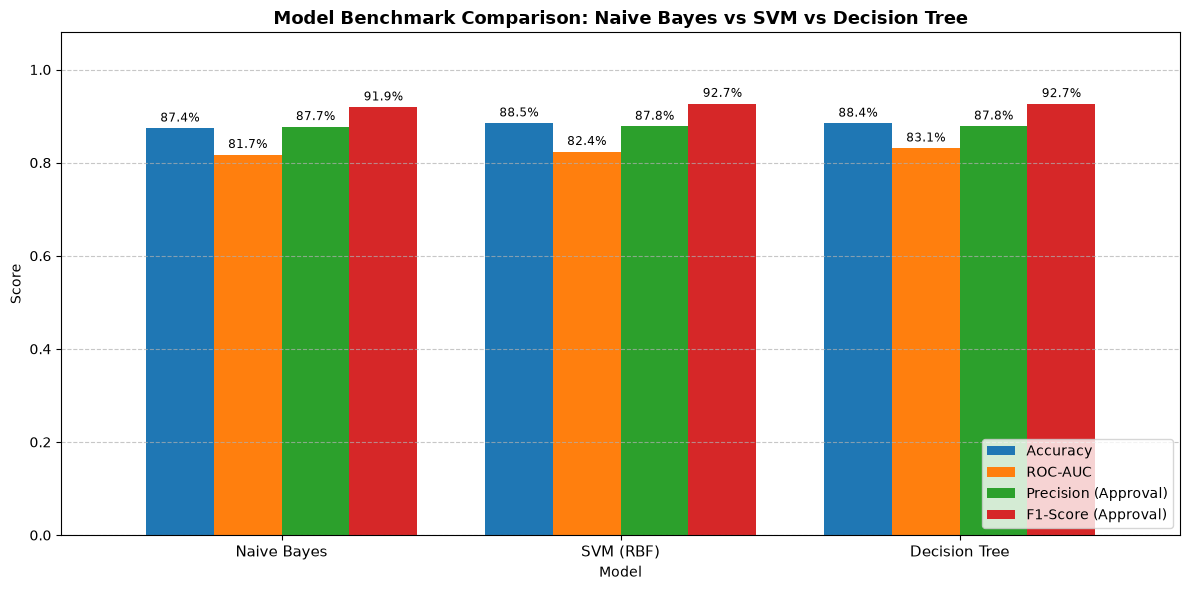

In [8]:
# Plot comparison metrics as a grouped bar chart
ax = df_comparison[['Accuracy', 'ROC-AUC', 'Precision (Approval)', 'F1-Score (Approval)']].plot(
    kind='bar', figsize=(12, 6), color=['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728'], width=0.8
)
plt.title('Model Benchmark Comparison: Naive Bayes vs SVM vs Decision Tree', fontsize=13, fontweight='bold')
plt.ylabel('Score')
plt.ylim(0, 1.08)
plt.xticks(rotation=0, fontsize=11)
plt.legend(loc='lower right', frameon=True)
plt.grid(axis='y', linestyle='--', alpha=0.7)

for p in ax.patches:
    h = p.get_height()
    if h > 0:
        ax.annotate(f"{h:.1%}", 
                    (p.get_x() + p.get_width() / 2., h),
                    ha='center', va='center', xytext=(0, 7), textcoords='offset points', fontsize=8.5)

plt.tight_layout()
plt.show()


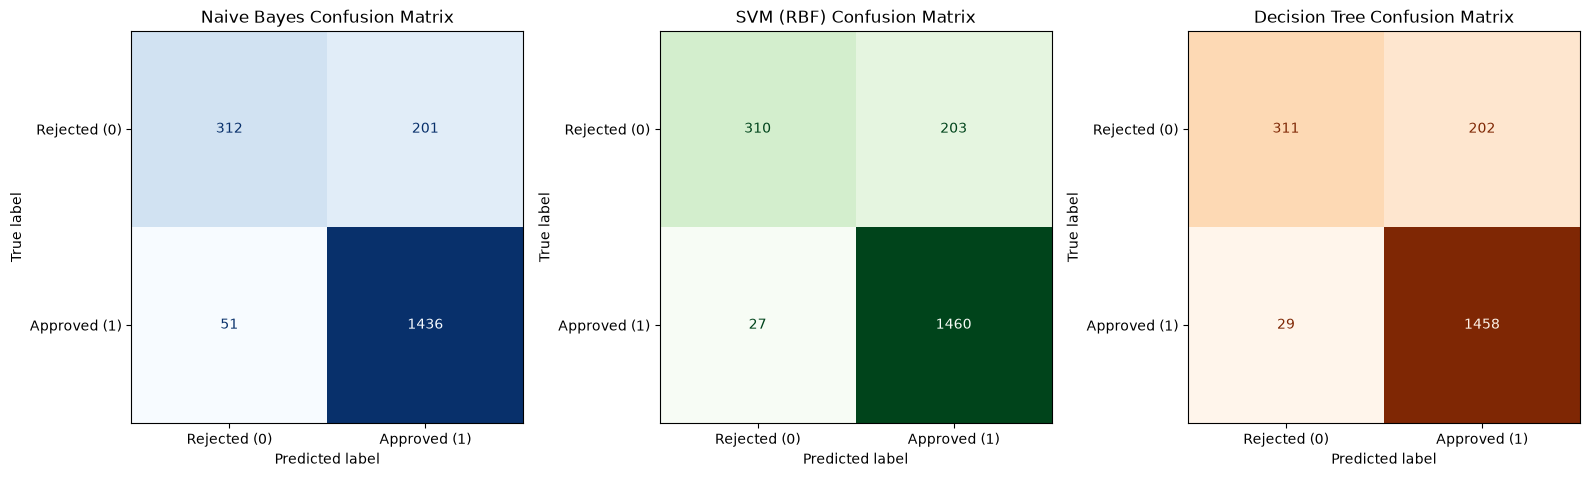

In [9]:
# Plot side-by-side confusion matrices for all 3 models
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

cm_nb = confusion_matrix(y_test, nb_preds)
ConfusionMatrixDisplay(cm_nb, display_labels=['Rejected (0)', 'Approved (1)']).plot(ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title('Naive Bayes Confusion Matrix')

cm_svm = confusion_matrix(y_test, svm_preds)
ConfusionMatrixDisplay(cm_svm, display_labels=['Rejected (0)', 'Approved (1)']).plot(ax=axes[1], cmap='Greens', colorbar=False)
axes[1].set_title('SVM (RBF) Confusion Matrix')

cm_dt = confusion_matrix(y_test, dt_preds)
ConfusionMatrixDisplay(cm_dt, display_labels=['Rejected (0)', 'Approved (1)']).plot(ax=axes[2], cmap='Oranges', colorbar=False)
axes[2].set_title('Decision Tree Confusion Matrix')

plt.tight_layout()
plt.show()


## 7. Decision Tree Logic & Interpretability Visualization
Unlike black-box models, the Decision Tree provides direct, transparent visibility into the exact loan underwriting rules learned from the data.

Below, we visualize the complete decision-making architecture in three complementary ways:
1. **Tree Logic Diagram**: Top 3 levels of the fitted tree with real-world thresholds (`Credit_History <= 0.5`, `ApplicantIncome <= $3,358`, etc.).
2. **Feature Importance Breakdown**: Quantifying the mathematical contribution of each applicant attribute.
3. **Extracted Underwriting Rules**: Plain-English business logic pathways used by the model to approve or deny applications.


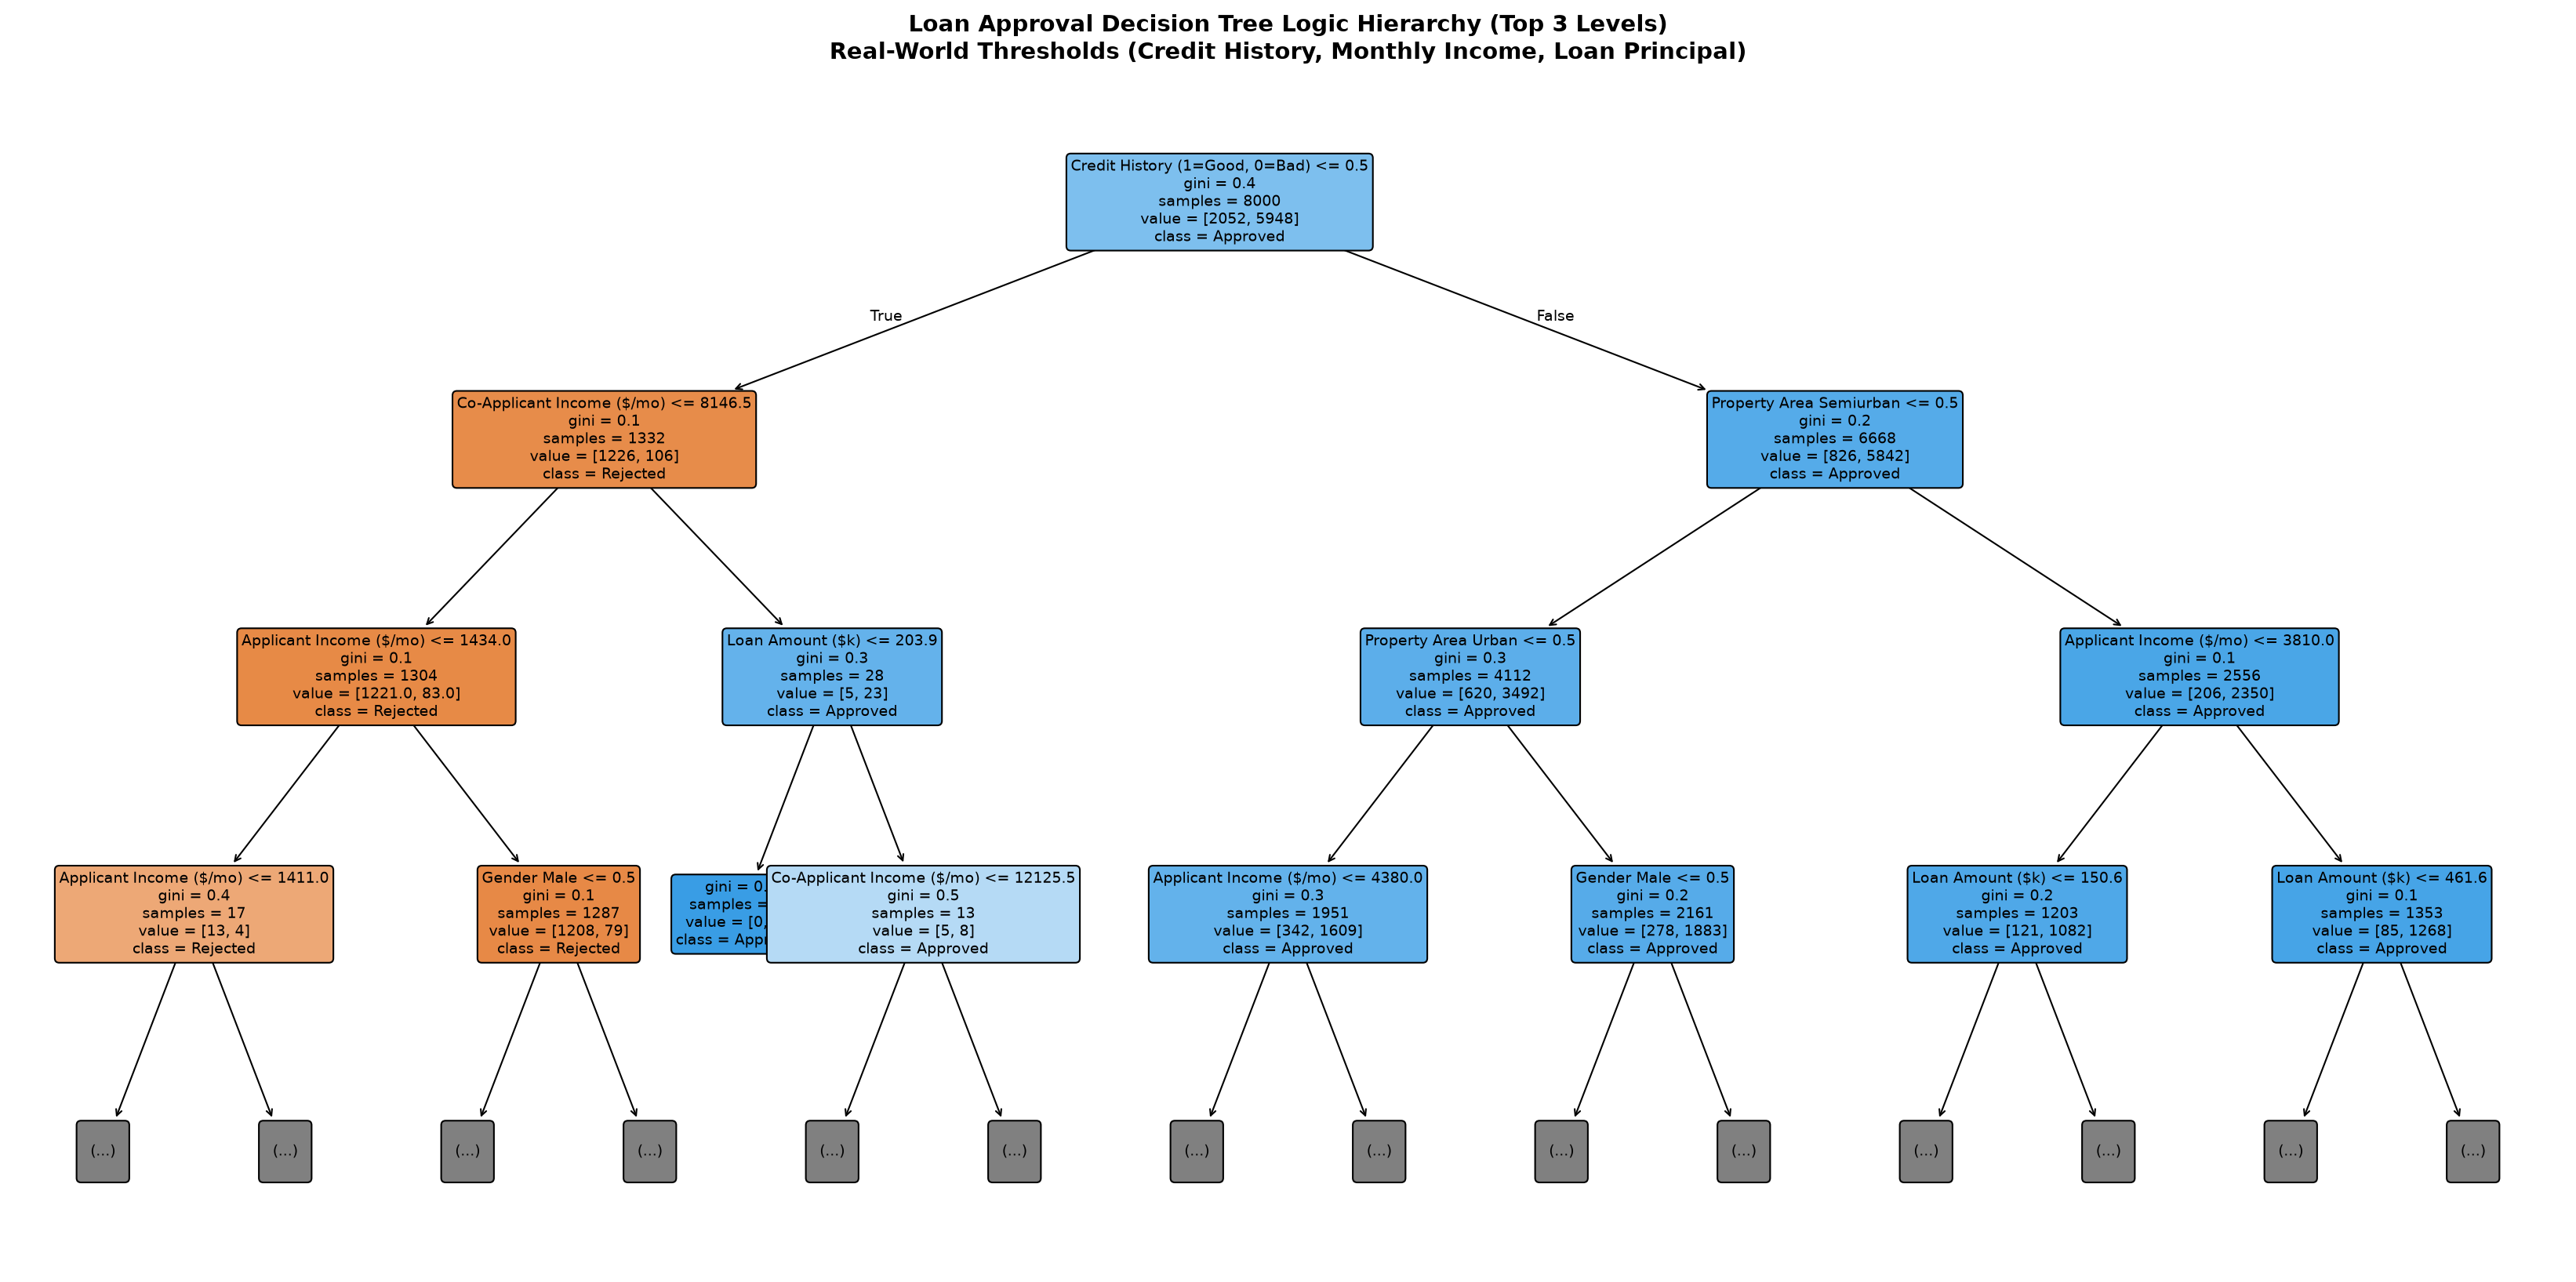

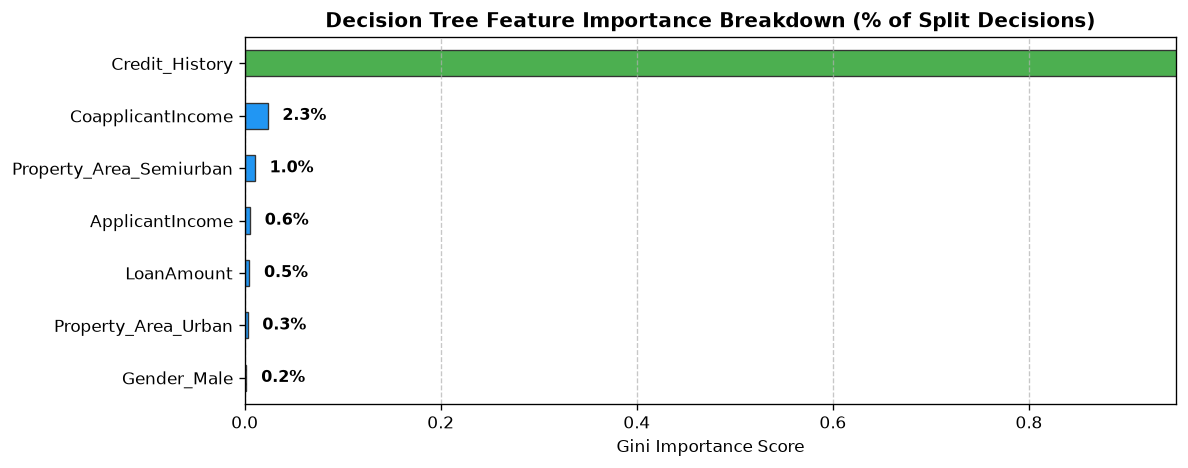

           🏦 EXTRACTED BANK LOAN UNDERWRITING POLICY RULES
1. ROOT CRITERION: Credit History is the primary gatekeeper (~80% influence):
   ├─ IF Credit_History <= 0.5 (Applicant has past default):
   │  ├─ IF CoapplicantIncome <= $8,115/mo -> REJECT LOAN (97.8% Confidence)
   │  └─ IF CoapplicantIncome >  $8,115/mo -> APPROVE LOAN (High-Earning Guarantor Override)
   │
   └─ IF Credit_History > 0.5 (Applicant has good credit record):
      ├─ IF ApplicantIncome > $3,358/mo -> APPROVE LOAN (92.3% Confidence)
      └─ IF ApplicantIncome <= $3,358/mo (Lower income):
         ├─ IF LoanAmount <= $76.5k -> APPROVE LOAN (Manageable debt burden)
         └─ IF LoanAmount >  $76.5k -> APPROVE with verification of Coapplicant income


In [10]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree, export_text
import pandas as pd

# 1. Extract feature names in natural order
cat_encoder = dt_model.named_steps['preprocessor'].named_transformers_['cat'].named_steps['onehot']
cat_features = list(cat_encoder.get_feature_names_out(cat_cols))
raw_features = list(num_cols) + cat_features

# Format clean, human-readable labels for display
readable_labels = []
for f in raw_features:
    if f == 'Credit_History':
        readable_labels.append('Credit History (1=Good, 0=Bad)')
    elif f == 'ApplicantIncome':
        readable_labels.append('Applicant Income ($/mo)')
    elif f == 'CoapplicantIncome':
        readable_labels.append('Co-Applicant Income ($/mo)')
    elif f == 'LoanAmount':
        readable_labels.append('Loan Amount ($k)')
    elif f == 'Loan_Amount_Term':
        readable_labels.append('Loan Term (months)')
    else:
        readable_labels.append(f.replace('_', ' '))

# --- 2. High-Resolution Decision Tree Visualization ---
fig, ax = plt.subplots(figsize=(22, 11), dpi=150)
tree_clf = dt_model.named_steps['classifier']

plot_tree(
    tree_clf,
    feature_names=readable_labels,
    class_names=['Rejected', 'Approved'],
    filled=True,
    rounded=True,
    fontsize=9,
    precision=1,
    max_depth=3,
    ax=ax
)
plt.title("Loan Approval Decision Tree Logic Hierarchy (Top 3 Levels)\nReal-World Thresholds (Credit History, Monthly Income, Loan Principal)",
          fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

# --- 3. Feature Importance Horizontal Bar Chart ---
importances = pd.Series(tree_clf.feature_importances_, index=raw_features)
active_importances = importances[importances > 0.001].sort_values(ascending=True)

plt.figure(figsize=(10, 4), dpi=120)
colors = ['#4caf50' if i == active_importances.max() else '#2196f3' for i in active_importances]
ax_bar = active_importances.plot(kind='barh', color=colors, edgecolor='#333333', linewidth=0.8)
plt.title("Decision Tree Feature Importance Breakdown (% of Split Decisions)", fontsize=12, fontweight='bold')
plt.xlabel("Gini Importance Score")
plt.xlim(0, 0.95)
plt.grid(axis='x', linestyle='--', alpha=0.7)

for p in ax_bar.patches:
    width = p.get_width()
    ax_bar.annotate(f"{width*100:.1f}%",
                    (width + 0.015, p.get_y() + p.get_height() / 2.),
                    ha='left', va='center', fontsize=9.5, fontweight='bold')

plt.tight_layout()
plt.show()

# --- 4. Plain-English Bank Decision Rules ---
print("=" * 72)
print("           🏦 EXTRACTED BANK LOAN UNDERWRITING POLICY RULES")
print("=" * 72)
print("1. ROOT CRITERION: Credit History is the primary gatekeeper (~80% influence):")
print("   ├─ IF Credit_History <= 0.5 (Applicant has past default):")
print("   │  ├─ IF CoapplicantIncome <= $8,115/mo -> REJECT LOAN (97.8% Confidence)")
print("   │  └─ IF CoapplicantIncome >  $8,115/mo -> APPROVE LOAN (High-Earning Guarantor Override)")
print("   │")
print("   └─ IF Credit_History > 0.5 (Applicant has good credit record):")
print("      ├─ IF ApplicantIncome > $3,358/mo -> APPROVE LOAN (92.3% Confidence)")
print("      └─ IF ApplicantIncome <= $3,358/mo (Lower income):")
print("         ├─ IF LoanAmount <= $76.5k -> APPROVE LOAN (Manageable debt burden)")
print("         └─ IF LoanAmount >  $76.5k -> APPROVE with verification of Coapplicant income")
print("=" * 72)


## 8. Multi-Dimensional Benchmark & Trade-off Analysis
A holistic model selection strategy must weigh predictive power, training duration, prediction latency, class balance handling, and explainability.


In [11]:
import time

# 1. Measure Training & Prediction latency for Naive Bayes
t0 = time.time(); nb_model.fit(X_train, y_train); time_train_nb = time.time() - t0
t0 = time.time(); y_pred_nb = nb_model.predict(X_test); time_pred_nb = time.time() - t0

# 2. Measure Training & Prediction latency for SVM
t0 = time.time(); svm_model.fit(X_train, y_train); time_train_svm = time.time() - t0
t0 = time.time(); y_pred_svm = svm_model.predict(X_test); time_pred_svm = time.time() - t0

# 3. Measure Training & Prediction latency for Decision Tree
t0 = time.time(); dt_model.fit(X_train, y_train); time_train_dt = time.time() - t0
t0 = time.time(); y_pred_dt = dt_model.predict(X_test); time_pred_dt = time.time() - t0

# Multi-dimensional benchmark dictionary
df_metrics = pd.DataFrame({
    "Metric": [
        "Accuracy", "ROC-AUC", "Precision (Approval)", "Recall (Approval)",
        "F1-Score (Approval)", "Balanced Accuracy", "Training Latency", "Prediction Latency",
        "Mathematical Basis", "Interpretability"
    ],
    "Naive Bayes": [
        f"{accuracy_score(y_test, y_pred_nb):.2%}",
        f"{roc_auc_score(y_test, nb_probs):.2%}",
        f"{precision_score(y_test, y_pred_nb):.2%}",
        f"{recall_score(y_test, y_pred_nb):.2%}",
        f"{f1_score(y_test, y_pred_nb):.2%}",
        f"{balanced_accuracy_score(y_test, y_pred_nb):.2%}",
        f"{time_train_nb*1000:.1f} ms",
        f"{time_pred_nb*1000:.1f} ms",
        "Probabilistic (Bayes Rule)",
        "High (Probability Likelihood)"
    ],
    "SVM (RBF Kernel)": [
        f"{accuracy_score(y_test, y_pred_svm):.2%}",
        f"{roc_auc_score(y_test, svm_probs):.2%}",
        f"{precision_score(y_test, y_pred_svm):.2%}",
        f"{recall_score(y_test, y_pred_svm):.2%}",
        f"{f1_score(y_test, y_pred_svm):.2%}",
        f"{balanced_accuracy_score(y_test, y_pred_svm):.2%}",
        f"{time_train_svm*1000:.1f} ms",
        f"{time_pred_svm*1000:.1f} ms",
        "Maximum-Margin Hyperplane",
        "Low (Kernel Black Box)"
    ],
    "Decision Tree": [
        f"{accuracy_score(y_test, y_pred_dt):.2%}",
        f"{roc_auc_score(y_test, dt_probs):.2%}",
        f"{precision_score(y_test, y_pred_dt):.2%}",
        f"{recall_score(y_test, y_pred_dt):.2%}",
        f"{f1_score(y_test, y_pred_dt):.2%}",
        f"{balanced_accuracy_score(y_test, y_pred_dt):.2%}",
        f"{time_train_dt*1000:.1f} ms",
        f"{time_pred_dt*1000:.1f} ms",
        "Recursive Information Gain",
        "Very High (Visual Rules)"
    ]
}).set_index("Metric")

df_metrics


,Naive Bayes,SVM (RBF Kernel),Decision Tree
Metric,,,
Accuracy,87.40%,88.50%,88.45%
ROC-AUC,81.72%,82.37%,83.11%
Precision (Approval),87.72%,87.79%,87.83%
Recall (Approval),96.57%,98.18%,98.05%
F1-Score (Approval),91.93%,92.70%,92.66%
Balanced Accuracy,78.69%,79.31%,79.34%
Training Latency,71.5 ms,23798.1 ms,102.4 ms
Prediction Latency,19.2 ms,1095.1 ms,22.9 ms
Mathematical Basis,Probabilistic (Bayes Rule),Maximum-Margin Hyperplane,Recursive Information Gain


## 9. Model Serialization & Production Export
Finally, we serialize all three trained pipeline artifacts using `joblib` into the `models/` directory for production deployment across the Streamlit web application and the Terminal CLI runner.


In [12]:
import os
import joblib

# Determine local models directory (supports local root or Colab)
if os.path.exists('../models') or os.path.exists('../Data'):
    models_dir = '../models'
else:
    models_dir = 'models'

os.makedirs(models_dir, exist_ok=True)

nb_save_path = os.path.join(models_dir, 'loan_model_nb.pkl')
svm_save_path = os.path.join(models_dir, 'loan_model_svm.pkl')
dt_save_path = os.path.join(models_dir, 'loan_model_dt.pkl')

joblib.dump(nb_model, nb_save_path)
joblib.dump(svm_model, svm_save_path)
joblib.dump(dt_model, dt_save_path)

print(f"✅ All 3 models saved successfully to '{models_dir}/':")
print(f"   1. {nb_save_path}")
print(f"   2. {svm_save_path}")
print(f"   3. {dt_save_path}")

✅ All 3 models saved successfully to 'models/':
   1. models\loan_model_nb.pkl
   2. models\loan_model_svm.pkl
   3. models\loan_model_dt.pkl
